# Example 3.3 — Mutant vs wild type (EGFR T790M)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:22Z
- **Contents:** 1 exchange · 3 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/3.3-mutant-vs-wild-type-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 3.3-mutant-vs-wild-type-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 3.3-mutant-vs-wild-type-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/3.3-mutant-vs-wild-type-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 3.3-mutant-vs-wild-type-notebook-rerun.ipynb 3.3-mutant-vs-wild-type-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Compare inhibitors of EGFR wild type with the T790M mutant.

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:21 UTC
await replay.call(1, 'search_targets', {'query': 'EGFR', 'organism': 'Homo sapiens'},
                  sha256='5566f990ce0794d4346e8e871914fee0fedd74c2c1d74ee7ccd09953b8554b9e')

**Call 1** · `search_targets` · recorded result · sha256 `5566f990ce07…`

_20 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 520 | Epidermal growth factor receptor | P00533 | P00533 | Homo sapiens | Receptor Kinase Domain | 23267 | 14127 | EGFR |
| polymer | 60 | Epidermal growth factor receptor \[T790M,L858R\] | P00533 | P00533\[T790M,L858R\] | Homo sapiens |  | 1536 | 1276 | EGFR |
| polymer | 1058 | Epidermal growth factor receptor \[L858R,T790M,C797S\] | P00533 | P00533\[L858R,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 703 | 679 | EGFR |
| polymer | 1214 | Epidermal growth factor receptor \[L858R,C797S\] | P00533 | P00533\[L858R,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 684 | 683 | EGFR |
| polymer | 51 | Epidermal growth factor receptor \[L858R\] | P00533 | P00533\[L858R\] | Homo sapiens |  | 678 | 646 | EGFR |
| polymer | 1198 | Epidermal growth factor receptor \[1-18,20-1210,T790M,C797S\] | P00533 | P00533\[1-18,20-1210,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 478 | 451 | EGFR |
| polymer | 1197 | Epidermal growth factor receptor \[1-18,20-1210,C797S\] | P00533 | P00533\[1-18,20-1210,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 428 | 415 | EGFR |
| polymer | 1253 | Epidermal growth factor receptor \[1-770,'NPG',771-1210\] | P00533 | P00533\[1-770,'NPG',771-1210\] | Homo sapiens | Enzyme Catalytic Domain | 415 | 410 | EGFR |
| polymer | 1252 | Epidermal growth factor receptor \[1-770,'SVD',771-1210\] | P00533 | P00533\[1-770,'SVD',771-1210\] | Homo sapiens | Enzyme Catalytic Domain | 302 | 282 | EGFR |
| polymer | 535 | Epidermal growth factor receptor \[1-745,751-1210\] | P00533 | P00533\[1-745,751-1210\] | Homo sapiens | Enzyme Catalytic Domain | 246 | 245 | EGFR |
| polymer | 243 | Epidermal growth factor receptor \[T790M\] | P00533 | P00533\[T790M\] | Homo sapiens | Enzyme | 229 | 213 | EGFR |
| polymer | 1148 | Epidermal growth factor receptor \[695-1022,T790M,C797S,L858R\] | P00533 | P00533\[695-1022,T790M,C797S,L858R\] | Homo sapiens | Enzyme Catalytic Domain | 151 | 130 | EGFR |
| polymer | 1200 | Epidermal growth factor receptor \[1-18,20-1210\] | P00533 | P00533\[1-18,20-1210\] | Homo sapiens | Enzyme Catalytic Domain | 150 | 150 | EGFR |
| polymer | 1150 | Epidermal growth factor receptor \[695-1022\] | P00533 | P00533\[695-1022\] | Homo sapiens | Enzyme Catalytic Domain | 142 | 124 | EGFR |
| polymer | 1201 | Epidermal growth factor receptor \[1-18,20-1210,T790M\] | P00533 | P00533\[1-18,20-1210,T790M\] | Homo sapiens | Enzyme Catalytic Domain | 95 | 83 | EGFR |
| polymer | 1217 | Epidermal growth factor receptor \[669-770,'SVD',771-1210\] | P00533 | P00533\[669-770,'SVD',771-1210\] | Homo sapiens | Enzyme Catalytic Domain | 73 | 45 | EGFR |
| polymer | 1251 | Epidermal growth factor receptor \[S768I\] | P00533 | P00533\[S768I\] | Homo sapiens | Enzyme Catalytic Domain | 58 | 58 | EGFR |
| polymer | 1254 | Epidermal growth factor receptor \[1-769,'SVD',770-1210\] | P00533 | P00533\[1-769,'SVD',770-1210\] | Homo sapiens | Enzyme Catalytic Domain | 58 | 58 | EGFR |
| polymer | 1255 | Epidermal growth factor receptor \[1-769,'SV',770-1210\] | P00533 | P00533\[1-769,'SV',770-1210\] | Homo sapiens | Enzyme Catalytic Domain | 58 | 58 | EGFR |
| polymer | 1127 | Epidermal growth factor receptor \[695-745,751-1022,T790M,C797S\] | P00533 | P00533\[695-745,751-1022,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 49 | 49 | EGFR |


In [ ]:
# Call 2 · find_ligands_for_target · ran 2026-11-24 04:55:21 UTC
await replay.call(2, 'find_ligands_for_target', {'uniprot': 'P00533', 'include_variants': True},
                  sha256='575f965ef1219e9b6924514543d64ebf2c430f87867379c02ac99929e08270bd')

**Call 2** · `find_ligands_for_target` · recorded result · sha256 `575f965ef121…`

_50 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51382967 | IC50 | = | 0.002 | nM | 11.7 | 50029668 | Osimertinib | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2065920 (CHEMBL4721173) | 29523467 | 10.1016/j.bmc.2018.02.022 | 2018 | 0.43 | 7.19 |  | 305 |
| 5350 | IC50 | = | 0.003 | nM | 11.52 | 3585 | Benzoquinazoline deriv. 23 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.72 | 6.23 |  | 1 |
| 5321 | IC50 | = | 0.006 | nM | 11.22 | 3556 | PD153035 Analog | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Inhibition Assay | 8568816 | 10.1021/jm9503613 | 1996 | 0.64 | 6.29 |  | 5 |
| 5369 | IC50 | = | 0.006 | nM | 11.22 | 3604 | Pyrido\[3,4-d\]pyrimidine 7g | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8627606 | 10.1021/jm9508651 | 1996 | 0.73 | 7.62 |  | 2 |
| 50029862 | Ki | = | 0.006 | nM | 11.22 | 3032 | PD153035 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_473565 (CHEMBL940057) | 18077363 | 10.1073/pnas.0708800104 | 2007 | 0.7 | 7.07 |  | 45 |
| 1488052 | IC50 | = | 0.007 | nM | 11.15 | 717491 | US20250034165, Example 28 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.76 |  | 5 |
| 1488133 | IC50 | = | 0.007 | nM | 11.15 | 717507 | US20250034165, Example 44 | 1788 |  | Epidermal growth factor receptor \[T790M,C797S,L858R\] | P00533\[T790M,C797S,L858R\] |  |  |  | Inhibitory Activity for EGFR (L858R/T790M/C797S) Kinase | US20250034165-A1 |  | 2025 | 0.37 | 6.37 |  | 5 |
| 1488244 | IC50 | = | 0.007 | nM | 11.15 | 717530 | US20250034165, Example 79 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Inhibitory Activity for EGFR (L858R/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.39 | 5.77 |  | 5 |
| 5335 | IC50 | = | 0.008 | nM | 11.1 | 3570 | Anilinopyrimidine deriv. 7a | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.72 | 7.09 |  | 2 |
| 5368 | IC50 | = | 0.008 | nM | 11.1 | 3603 | PD158780 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8627606 | 10.1021/jm9508651 | 1996 | 0.76 | 7.53 |  | 3 |
| 1487998 | IC50 | = | 0.008 | nM | 11.1 | 717480 | US20250034165, Example 17 | 1788 |  | Epidermal growth factor receptor \[T790M,C797S,L858R\] | P00533\[T790M,C797S,L858R\] |  |  |  | Inhibitory Activity for EGFR (L858R/T790M/C797S) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.3 |  | 5 |
| 1488122 | IC50 | = | 0.008 | nM | 11.1 | 717505 | US20250034165, Example 42 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.71 |  | 5 |
| 1488227 | IC50 | = | 0.008 | nM | 11.1 | 717526 | US20250034165, Example 63 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.37 | 6.32 |  | 5 |
| 51528505 | IC50 | = | 0.008 | nM | 11.1 | 50615089 | CHEMBL5270693 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2299669 | 37197473 | 10.1021/acsmedchemlett.2c00514 | 2023 | 0.36 | 4.97 |  | 5 |
| 1488057 | IC50 | = | 0.009 | nM | 11.05 | 717492 | US20250034165, Example 29 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.43 |  | 5 |
| 1488117 | IC50 | = | 0.009 | nM | 11.05 | 717504 | US20250034165, Example 41 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.8 |  | 5 |
| 1488197 | IC50 | = | 0.009 | nM | 11.05 | 717520 | US20250034165, Example 57 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.39 | 7.06 |  | 5 |
| 1488202 | IC50 | = | 0.009 | nM | 11.05 | 717521 | US20250034165, Example 58 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.4 | 7.26 |  | 5 |
| 1488260 | IC50 | = | 0.009 | nM | 11.05 | 717533 | US20250034165, Example 82 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6.12 |  | 5 |
| 51613929 | IC50 | = | 0.009 | nM | 11.05 | 50651045 | CHEMBL5633067 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2497198 | 37499291 | 10.1016/j.ejmech.2023.115671 |  | 0.47 | 8.03 |  | 7 |
| 5337 | IC50 | = | 0.01 | nM | 11 | 3572 | Imidazoquinazoline deriv. 10 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 7.4 | 295.15 | Kinase Inhibition Assay | 8632415 | 10.1021/jm950692f | 1996 | 0.69 | 6.98 |  | 1 |
| 1160927 | IC50 | = | 0.01 | nM | 11 | 112499 | DACOMITINIB | 1200 |  | Epidermal growth factor receptor \[1-18,20-1210\] | P00533\[1-18,20-1210\] | Homo sapiens |  |  | pEGFR assay | WO2022090481 |  | 2022 | 0.46 | 5.84 |  | 30 |
| 1488072 | IC50 | = | 0.01 | nM | 11 | 717495 | US20250034165, Example 32 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.39 | 7.2 |  | 5 |
| 1488077 | IC50 | = | 0.01 | nM | 11 | 717496 | US20250034165, Example 33 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.86 |  | 5 |
| 1488177 | IC50 | = | 0.01 | nM | 11 | 717516 | US20250034165, Example 53 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.43 |  | 5 |
| 1488250 | IC50 | = | 0.01 | nM | 11 | 717531 | US20250034165, Example 80 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.34 | 5.29 |  | 5 |
| 1488279 | IC50 | = | 0.01 | nM | 11 | 717537 | US20250034165, Example 88 | 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens |  |  | Inhibitory Activity for EGFR (L858R/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.38 | 6.38 |  | 5 |
| 51352937 | IC50 | = | 0.01 | nM | 11 | 50322823 | AFATINIB | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2017352 (CHEMBL4670930) | 32931277 | 10.1021/acs.jmedchem.0c00870 | 2020 | 0.44 | 6.61 |  | 142 |
| 51528524 | IC50 | = | 0.01 | nM | 11 | 368374 | US10227342, Example 10 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2299670 | 37197473 | 10.1021/acsmedchemlett.2c00514 | 2023 | 0.35 | 5.92 |  | 19 |
| 1487932 | IC50 | = | 0.011 | nM | 10.96 | 717467 | US20250034165, Example 1 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.39 | 6.18 |  | 5 |
| 1488037 | IC50 | = | 0.011 | nM | 10.96 | 717488 | US20250034165, Example 25 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.34 | 5.26 |  | 5 |
| 1488042 | IC50 | = | 0.011 | nM | 10.96 | 717489 | US20250034165, Example 26 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.34 | 5.26 |  | 5 |
| 1488240 | IC50 | = | 0.011 | nM | 10.96 | 717529 | US20250034165, Example 72 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6.03 |  | 5 |
| 1488255 | IC50 | = | 0.011 | nM | 10.96 | 717532 | US20250034165, Example 81 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.34 | 6.41 |  | 5 |
| 1488012 | IC50 | = | 0.012 | nM | 10.92 | 717483 | US20250034165, Example 20 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6 |  | 5 |
| 1488107 | IC50 | = | 0.012 | nM | 10.92 | 717502 | US20250034165, Example 39 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6.06 |  | 5 |
| 1488097 | IC50 | = | 0.013 | nM | 10.89 | 717500 | US20250034165, Example 37 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6.03 |  | 5 |
| 1488137 | IC50 | = | 0.013 | nM | 10.89 | 717508 | US20250034165, Example 45 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6.47 |  | 5 |
| 1488142 | IC50 | = | 0.013 | nM | 10.89 | 717509 | US20250034165, Example 46 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.35 | 5.69 |  | 5 |
| 1488167 | IC50 | = | 0.013 | nM | 10.89 | 717514 | US20250034165, Example 51 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 5.72 |  | 5 |
| 1488182 | IC50 | = | 0.013 | nM | 10.89 | 717517 | US20250034165, Example 54 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.34 | 5.19 |  | 5 |
| 1488222 | IC50 | = | 0.013 | nM | 10.89 | 717525 | US20250034165, Example 62 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 6.11 |  | 5 |
| 1488235 | IC50 | = | 0.013 | nM | 10.89 | 717528 | US20250034165, Example 70 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.35 | 5.57 |  | 5 |
| 1488265 | IC50 | = | 0.013 | nM | 10.89 | 717534 | US20250034165, Example 83 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.35 | 5.57 |  | 5 |
| 1487937 | IC50 | = | 0.014 | nM | 10.85 | 717468 | US20250034165, Example 3 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.35 | 6.69 |  | 5 |
| 1487962 | IC50 | = | 0.014 | nM | 10.85 | 717473 | US20250034165, Example 10 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.35 | 5.93 |  | 5 |
| 1488027 | IC50 | = | 0.014 | nM | 10.85 | 717486 | US20250034165, Example 23 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 5.47 |  | 5 |
| 1488082 | IC50 | = | 0.014 | nM | 10.85 | 717497 | US20250034165, Example 34 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.37 | 6.66 |  | 5 |
| 1488102 | IC50 | = | 0.014 | nM | 10.85 | 717501 | US20250034165, Example 38 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 5.43 |  | 5 |
| 1488112 | IC50 | = | 0.014 | nM | 10.85 | 717503 | US20250034165, Example 40 | 1834 |  | Epidermal growth factor receptor \[1-18,20-745,751-1210,T790M\] | P00533\[1-18,20-745,751-1210,T790M\] |  |  |  | Inhibitory Activity for EGFR (d746-750 (d19)/T790M) Kinase | US20250034165-A1 |  | 2025 | 0.36 | 5.98 |  | 5 |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:21 UTC
sql = """
    WITH v AS (SELECT monomerid, polymerid, source_id, affinity_type, median(p_affinity) AS med_p, count(*) AS n, list(value ORDER BY value) AS vals FROM activity WHERE polymerid IN (520, 243) AND relation = '=' AND affinity_type IN ('Ki','Kd','IC50') AND source_id IS NOT NULL GROUP BY ALL), p AS (SELECT w.monomerid, w.source_id, w.affinity_type, w.med_p AS wt_p, w.n AS wt_n, w.vals AS wt_vals, m.med_p AS mut_p, m.n AS mut_n, m.vals AS mut_vals, round(m.med_p - w.med_p, 2) AS shift FROM v w JOIN v m ON w.monomerid = m.monomerid AND w.source_id = m.source_id AND w.affinity_type = m.affinity_type AND w.polymerid = 520 AND m.polymerid = 243) SELECT p.*, c.name AS compound_name, c.smiles FROM p JOIN compound c USING (monomerid) ORDER BY shift DESC, monomerid, source_id
    
"""
await replay.call(3, 'run_sql', {'sql': sql, 'limit': 500},
                  sha256='ef181e284c06a4d3caa73bc7d03e8e5858e90274c788819c6c0ecd987c7afc1b')

**Call 3** · `run_sql` · recorded result · sha256 `ef181e284c06…`

_64 rows_

| monomerid | source_id | affinity_type | wt_p | wt_n | wt_vals | mut_p | mut_n | mut_vals | shift | compound_name | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 391733 | US10300058-B2 | IC50 | 6.16 | 1 | 699.0 | 8.33 | 1 | 4.7 | 2.17 | N-(3-((2-((4-(1-acetyl-1,2,3,6-tetrahydropyridin-4-yl)-2-methoxyphenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1=CCN(CC1)C(C)=O \|t:34\| |
| 391745 | US10300058-B2 | IC50 | 2.89 | 1 | 1284000.0 | 5 | 1 | 9900.0 | 2.11 | N-(3-((2-((2-acetyl-1,2,3,4-tetrahydroisoquinoline-5-yl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | CC(=O)N1CCc2c(C1)cccc2Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F |
| 149404 | US10300058-B2 | IC50 | 6.74 | 4 | 145.0, 180.0, 180.0, 153000.0 | 8.785 | 4 | 1.3, 1.3, 2.1, 2500.0 | 2.05 | Rociletinib | CC(=O)N1CCN(CC1)c2ccc(c(c2)OC)Nc3ncc(c(n3)Nc4cccc(c4)NC(=O)C=C)C(F)(F)F |
| 391736 | US10300058-B2 | IC50 | 6 | 1 | 995.0 | 8.05 | 1 | 8.9 | 2.05 | N-(6-((2-((4-(1-acetyl-1,2,3,6-tetrahydropyridin-4-yl)-2-methoxyphenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)pyridin-2-yl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)n2)n1)C(F)(F)F)C1=CCN(CC1)C(C)=O \|t:34\| |
| 391740 | US10300058-B2 | IC50 | 3.17 | 1 | 683000.0 | 5.15 | 1 | 7100.0 | 1.98 | N-(3-((2-((4-(1-(3-fluoropropionyl)piperidin-4-yl)-2-methoxyphenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(CC1)C(=O)CCF |
| 391742 | US10300058-B2 | IC50 | 3.06 | 1 | 871000.0 | 5.02 | 1 | 9600.0 | 1.96 | N-(3-((2-((2-methoxy-4-(1-(methylsulfonyl)piperidin-4-yl)phenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(CC1)S(C)(=O)=O |
| 391732 | US10300058-B2 | IC50 | 6.26 | 1 | 552.0 | 8.21 | 1 | 6.2 | 1.95 | acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(CC1)C(C)=O |
| 391738 | US10300058-B2 | IC50 | 2.86 | 1 | 1369000.0 | 4.8 | 1 | 16000.0 | 1.94 | N-(3-((2-((2-acetyl-8-methoxy-1,2,3,4-tetrahydroisoquinoline-7-yl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1c(Nc2ncc(c(Nc3cccc(NC(=O)C=C)c3)n2)C(F)(F)F)ccc2CCN(Cc12)C(C)=O |
| 391739 | US10300058-B2 | IC50 | 3.53 | 1 | 294000.0 | 5.41 | 1 | 3900.0 | 1.88 | methyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(CCF)C(=O)C1 |
| 391743 | US10300058-B2 | IC50 | 4.14 | 1 | 73000.0 | 5.92 | 1 | 1200.0 | 1.78 | N-(3-((2-((2-methoxy-4-(4-morpholinopiperidin-1-yl)phenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)N1CCC(CC1)N1CCOCC1 |
| 391735 | US10300058-B2 | IC50 | 6.37 | 1 | 423.0 | 8.14 | 1 | 7.2 | 1.77 | N-(6-((2-((4-(1-acetylpiperidin-4-yl)-2-methoxyphenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)pyridin-2-yl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)n2)n1)C(F)(F)F)C1CCN(CC1)C(C)=O |
| 391746 | US10300058-B2 | IC50 | 4.09 | 1 | 82000.0 | 5.85 | 1 | 1400.0 | 1.76 | N-(3-((2-((2-methoxy-4-(1-(oxetan-3-yl)piperidin-4-yl)phenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(CC1)C1COC1 |
| 391731 | US10300058-B2 | IC50 | 6.49 | 1 | 323.0 | 8.24 | 1 | 5.7 | 1.75 | pyrimidin-4-yl)amino)pyridin-2-yl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)n2)n1)C(F)(F)F)N1CCN(CC1)C(C)=O |
| 391737 | US10300058-B2 | IC50 | 3.48 | 1 | 332000.0 | 5.21 | 1 | 6200.0 | 1.73 | N-(3-((2-((4-(8-acetyl-3,8-diazabicyclo\[3.2.1\]octan-3-yl)-2-methoxyphenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)N1CC2CCC(C1)N2C(C)=O |
| 391734 | US10300058-B2 | IC50 | 6.19 | 1 | 640.0 | 7.89 | 1 | 13.0 | 1.7 | N-(3-((2-((2-acetyl-7-methoxy-1,2,3,4-tetrahydroisoquinolin-6-yl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc2CN(CCc2cc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C(C)=O |
| 391741 | US10300058-B2 | IC50 | 4.6 | 1 | 25000.0 | 6.29 | 1 | 510.0 | 1.69 | pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(CCF)CC1 |
| 391747 | US10300058-B2 | IC50 | 3.8 | 1 | 159000.0 | 5.44 | 1 | 3600.0 | 1.64 | N-(3-((2-((2-methoxy-4-(3-(methylsulfonyl)propoxy)phenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(OCCCS(C)(=O)=O)ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F |
| 378885 | US10266537-B2 | IC50 | 6.19 | 1 | 651.0 | 7.72 | 1 | 19.0 | 1.53 | US10266537, Compound 93 | Cc1ccc(NC(=O)c2ccc(C)c(C(F)(F)F)c2)cc1C#Cc1nn(\[C@H\]2CC\[C@H\](O)CC2)c2ncnc(N)c12 |
| 391744 | US10300058-B2 | IC50 | 4.96 | 1 | 11000.0 | 6.49 | 1 | 320.0 | 1.53 | N-(3-((2-((2-methoxy-4-(1-methylpiperidin-4-yl)phenyl)amino)-5-(trifluoromethyl)pyrimidin-4-yl)amino)phenyl)acrylamide | COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1CCN(C)CC1 |
| 270539 | US10059688-B2 | IC50 | 6.12 | 1 | 756.0 | 7.64 | 1 | 23.0 | 1.52 | 2-(2-(5-chloro-2-(3-methoxy- 4-(4-methylpiperazin-1-yl) phenylamino)pyrimidin-4- ylamino)phenyl)-N,N- dimethyl-2-oxoacetamide | COc1cc(Nc2ncc(Cl)c(Nc3ccccc3C(=O)C(=O)N(C)C)n2)ccc1N1CCN(C)CC1 |
| 270543 | US10059688-B2 | IC50 | 6.4 | 1 | 397.0 | 7.92 | 1 | 12.0 | 1.52 | US9783524, Example 115 | CN(C)CCOc1ccc(Nc2ncc(Cl)c(Nc3ccccc3C(=O)C(=O)N(C)C)n2)cc1NC(=O)C=C |
| 270541 | US10059688-B2 | IC50 | 6.29 | 1 | 513.0 | 7.8 | 1 | 16.0 | 1.51 | US10059688, Example 74 | CN(C)C(=O)C(=O)c1ccccc1Nc1cc(Cl)ccc1Cl |
| 270542 | US10059688-B2 | IC50 | 6.45 | 1 | 354.0 | 7.82 | 1 | 15.0 | 1.37 | 2-(2-(2-(4-acryloyl-3,4- dihydro-2H-benzo\[b\]\[1,4\] oxazin-6-ylamino)-5- chloropyrimidin-4- ylamino)phenyl)-N,N- dimethyl-2-oxoacetamide | CN(C)C(=O)C(=O)c1ccccc1Nc1nc(Nc2ccc3OCCN(C(=O)C=C)c3c2)ncc1Cl |
| 270540 | US10059688-B2 | IC50 | 6.56 | 1 | 273.0 | 7.82 | 1 | 15.0 | 1.26 | N-(3-(5-chloro-4-(2-(2- (dimethylamino)-2-oxoacetyl) phenylamino)pyrimidin-2- ylamino)-4-methoxyphenyl) acrylamide | COc1ccc(NC(=O)C=C)cc1Nc1ncc(Cl)c(Nc2ccccc2C(=O)C(=O)N(C)C)n1 |
| 270544 | US10059688-B2 | IC50 | 7.11 | 1 | 78.0 | 8.29 | 1 | 5.13 | 1.18 | 2-(2-(5-chloro-2-(4-(4- (dimethylamino)piperidin- 1-yl)-3-methoxyphenylamino) pyrimidin-4-ylamino)phenyl)- N,N-dimethyl-2-oxoacetamide | COc1cc(Nc2ncc(Cl)c(Nc3ccccc3C(=O)C(=O)N(C)C)n2)ccc1N1CCC(CC1)N(C)C |
| 270538 | US10059688-B2 | IC50 | 7.35 | 1 | 45.0 | 8.39 | 1 | 4.08 | 1.04 | US9783524, Example 4 | COc1cc(ccc1Nc1ncc(Cl)c(Nc2ccccc2C(=O)C(N)=O)n1)N1CCC(CC1)N(C)C |
| 228116 | US9556191-B2 | IC50 | 7.22 | 1 | 60.4 | 8.07 | 1 | 8.5 | 0.85 | (e)-n-(4-((3-chloro-4-(pyridin-2-ylmethoxy)phenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4 ar,7as)tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 195864 | US9670213-B2 | IC50 | 7.21 | 1 | 61.0 | 7.96 | 1 | 11.0 | 0.75 | US9670213, Compound 009 4-(dimethylamino)-N-(4-(2-(4-methoxyphenylamino)-7-oxo-8(7H)-pteridin-yl)phenyl)-2-buteneamide | COc1ccc(Nc2ncc3ncc(=O)n(-c4ccc(NC(=O)\\C=C\\CN(C)C)cc4)c3n2)cc1 |
| 228117 | US9556191-B2 | IC50 | 7.74 | 1 | 18.4 | 8.38 | 1 | 4.2 | 0.64 | (e)-n-(4-((3-chloro-4-(pyridin-2-ylmethoxy)phenyl)amino)-7-ethoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | CCOc1cc2ncnc(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 195865 | US9670213-B2 | IC50 | 5.09 | 1 | 8086.0 | 5.65 | 1 | 2253.0 | 0.56 | US9670213, Compound 010 4-(dimethylamino)-N-(3-(2-(4-methoxyphenylamino)-7-oxo-8(7H)-pteridin-yl)phenyl)-2-buteneamide | COc1ccc(Nc2ncc3ncc(=O)n(-c4cccc(NC(=O)\\C=C\\CN(C)C)c4)c3n2)cc1 |
| 228121 | US9556191-B2 | IC50 | 7.4 | 1 | 40.1 | 7.84 | 1 | 14.5 | 0.44 | (e)-n-(7-ethoxy-4-((1-(3-fluorobenzyl)-1h-indazol-5-yl)amino)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | CCOc1cc2ncnc(Nc3ccc4n(Cc5cccc(F)c5)ncc4c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 368444 | US10227342-B2 | IC50 | 6.12 | 1 | 750.0 | 6.52 | 1 | 300.0 | 0.4 | US10227342, Example 75 | COC(=O)c1cnc(Nc2cc(NC(=O)C=C)c(F)cc2OC)nc1-c1cn(N(C)C)c2ccccc12 |
| 368465 | US10227342-B2 | IC50 | 6.12 | 1 | 750.0 | 6.52 | 1 | 300.0 | 0.4 | US10227342, Example 93 | COCCNC(=O)c1c(-c2ccnc(Nc3cc(NC(=O)C=C)c(cc3OC)N(C)CCN(C)C)n2)c2ccccc2n1C |
| 228118 | US9556191-B2 | IC50 | 8.07 | 1 | 8.6 | 8.23 | 1 | 5.9 | 0.16 | (e)-n-(4-((3-chloro-4-(pyridin-2-ylmethoxy)phenyl)amino)-7-(((s)-tetrahydrofuran-3-yl)oxy)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Clc1cc(Nc2ncnc3cc(O\[C@H\]4CCOC4)c(NC(=O)\\C=C\\CN4C\[C@H\]5OCCO\[C@H\]5C4)cc23)ccc1OCc1ccccn1 \|r\| |
| 228109 | US9556191-B2 | IC50 | 8.19 | 1 | 6.4 | 8.21 | 1 | 6.2 | 0.02 | (e)-n-(4-((3-chloro-4-fluorophenyl)amino)-7-ethoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxin\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | CCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 368368 | US10227342-B2 | IC50 | 6.52 | 2 | 300.0, 300.0 | 6.52 | 1 | 300.0 | 0 | US10227342, Example 4 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncnc(n1)-c1c(C2CCOCC2)n(C)c2ccccc12 |
| 368369 | US10227342-B2 | IC50 | 6.52 | 3 | 300.0, 300.0, 300.0 | 6.52 | 1 | 300.0 | 0 | US10227342, Example 5 | COOc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1c(-c2ccc(OCc3ccccn3)c(Cl)c2)n(C)c2ccccc12 |
| 397156 | US10596172-B2 | IC50 | 7.26 | 1 | 55.0 | 7.26 | 1 | 55.0 | 0 | US9987276, Compound I-56 | Cc1ccc(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 |
| 397156 | US11351168-B1 | IC50 | 7.26 | 1 | 55.0 | 7.26 | 1 | 55.0 | 0 | US9987276, Compound I-56 | Cc1ccc(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 |
| 397156 | US9987276-B2 | IC50 | 7.26 | 1 | 55.0 | 7.26 | 1 | 55.0 | 0 | US9987276, Compound I-56 | Cc1ccc(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 |
| 195858 | US9670213-B2 | IC50 | 5.1 | 1 | 8011.0 | 5.06 | 1 | 8698.0 | -0.04 | US9670213, Compound 003 N-(4-(2-(4-morpholino-phenylamino)-7-oxo-8(7H)-pteridin-yl)phenyl)acrylamide | C=CC(=O)Nc1ccc(cc1)-n1c2nc(Nc3ccc(cc3)N3CCOCC3)ncc2ncc1=O |
| 228112 | US9556191-B2 | IC50 | 7.81 | 1 | 15.4 | 7.65 | 1 | 22.6 | -0.16 | (e)-n-(4-((3-chloro-4-fluorophenyl)amino)-7-(2,2,2-trifluoroethoxy)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Fc1ccc(Nc2ncnc3cc(OCC(F)(F)F)c(NC(=O)\\C=C\\CN4C\[C@H\]5OCCO\[C@H\]5C4)cc23)cc1Cl \|r\| |
| 195857 | US9670213-B2 | IC50 | 6.35 | 1 | 446.0 | 6.18 | 1 | 665.0 | -0.17 | US9670213, Compound 002 N-(4-(2-(4-methoxyphenylamino)-7-oxo-8(7H)-pteridin-yl)phenyl)acrylamide | COc1ccc(Nc2ncc3ncc(=O)n(-c4ccc(NC(=O)C=C)cc4)c3n2)cc1 |
| 195861 | US9670213-B2 | IC50 | 7.96 | 1 | 11.0 | 7.72 | 1 | 19.0 | -0.24 | US9670213, Compound 006 N-(3-(2-(4-methoxyphenylamino)-7-oxo-8(7H)-pteridin-yl)phenyl) acrylamide | COc1ccc(Nc2ncc3ncc(=O)n(-c4cccc(NC(=O)C=C)c4)c3n2)cc1 |
| 228110 | US9556191-B2 | IC50 | 8.44 | 1 | 3.6 | 8.17 | 1 | 6.8 | -0.27 | (e)-n-(4-((3-chloro-4-fluorophenyl)amino)-7-(((s)-tetrahydrofuran-3-yl)oxy)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Fc1ccc(Nc2ncnc3cc(O\[C@H\]4CCOC4)c(NC(=O)\\C=C\\CN4C\[C@H\]5OCCO\[C@H\]5C4)cc23)cc1Cl \|r\| |
| 228115 | US9556191-B2 | IC50 | 7.66 | 1 | 22.0 | 7.33 | 1 | 47.3 | -0.33 | (e)-n-(4-((3-chloro-4-(pyridin-2-ylmethoxy)phenyl)amino)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Clc1cc(Nc2ncnc3ccc(NC(=O)\\C=C\\CN4C\[C@H\]5OCCO\[C@H\]5C4)cc23)ccc1OCc1ccccn1 \|r\| |
| 228127 | US9556191-B2 | IC50 | 8.48 | 1 | 3.3 | 8.15 | 1 | 7.0 | -0.33 | (e)-n-(4-((3,4-dichloro-2-fluorophenyl)amino)-7-(((s)-tetrahydrofuran-3-yl)oxy)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Fc1c(Cl)c(Cl)ccc1Nc1ncnc2cc(O\[C@H\]3CCOC3)c(NC(=O)\\C=C\\CN3C\[C@H\]4OCCO\[C@H\]4C3)cc12 \|r\| |
| 368407 | US10227342-B2 | IC50 | 6.52 | 2 | 300.0, 300.0 | 6.12 | 1 | 750.0 | -0.4 | US10227342, Example 40 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(N(C)C(=O)C(C)C)c(n1)-c1cn(C)c2ccccc12 |
| 228107 | US9556191-B2 | IC50 | 8.49 | 1 | 3.2 | 8.08 | 1 | 8.3 | -0.41 | (E)-N-(4-((3-Chloro-4-fluorophenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4aR,7aS)-tetrahydro-2H-\[1,4\]dioxin\[2,3-c\]pyrrol-6(3H)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 |
| 228113 | US9556191-B2 | IC50 | 8.32 | 1 | 4.8 | 7.9 | 1 | 12.5 | -0.42 | (e)-n-(4-((3-chloro-4-fluorophenyl)amino)-7-(methoxy-d3)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro 2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228120 | US9556191-B2 | IC50 | 8.1 | 1 | 7.9 | 7.64 | 1 | 22.9 | -0.46 | (e)-n-(4-((1-(3-fluorobenzyl)-1h-indazol-5-yl)amino)-7-methoxyquinazolin-6-yl)-4-((4ar,7as)-tetra hydro-2h-\[1,4\]dioxin\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc4n(Cc5cccc(F)c5)ncc4c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228124 | US9556191-B2 | IC50 | 8.68 | 1 | 2.1 | 8.19 | 1 | 6.4 | -0.49 | (e)-n-(4-((3,4-dichloro-2-fluorophenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228125 | US9556191-B2 | IC50 | 8.92 | 1 | 1.2 | 8.4 | 1 | 4.0 | -0.52 | (e)-n-(4-((3,4-dichloro-2-fluorophenyl)amino)-7-ethoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | CCOc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228126 | US9556191-B2 | IC50 | 8.82 | 1 | 1.5 | 8.3 | 1 | 5.0 | -0.52 | (e)-n-(4-((3,4-dichloro-2-fluorophenyl)amino)-7-(2-methoxyethoxy)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COCCOc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 5447 | US10106508-B2 | IC50 | 8.2 | 1 | 6.3 | 7.65 | 1 | 22.5 | -0.55 | Iressa | COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F |
| 228108 | US9556191-B2 | IC50 | 8.37 | 1 | 4.3 | 7.8 | 1 | 16.0 | -0.57 | (e)-n-(4-((3-chloro-4-fluorophenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4as,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228122 | US9556191-B2 | IC50 | 7.65 | 1 | 22.6 | 7.06 | 1 | 87.3 | -0.59 | (e)-n-(4-((3-chloro-4-((3-fluorobenzyl)oxy)phenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(OCc4cccc(F)c4)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228123 | US9556191-B2 | IC50 | 7.5 | 1 | 31.9 | 6.88 | 1 | 133.0 | -0.62 | (e)-n-(4-((3-chloro-4-((3-fluorobenzyl)oxy)phenyl)amino)-7-ethoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | CCOc1cc2ncnc(Nc3ccc(OCc4cccc(F)c4)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228111 | US9556191-B2 | IC50 | 8.74 | 1 | 1.8 | 8.06 | 1 | 8.7 | -0.68 | (e)-n-(4-((3-chloro-4-fluorophenyl)amino)-7-(2-methoxyethoxy)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 228119 | US9556191-B2 | IC50 | 7.85 | 1 | 14.0 | 7.05 | 1 | 89.3 | -0.8 | (e)-n-(4-((1-(3-fluorobenzyl)-1h-indazol-5-yl)amino)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxin\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Fc1cccc(Cn2ncc3cc(Nc4ncnc5ccc(NC(=O)\\C=C\\CN6C\[C@H\]7OCCO\[C@H\]7C6)cc45)ccc23)c1 \|r\| |
| 228114 | US9556191-B2 | IC50 | 7.82 | 1 | 15.0 | 6.5 | 1 | 317.0 | -1.32 | (e)-n-(4-((3-chloro-4-((3-fluorobenzyl)oxy)phenyl)amino)quinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | Fc1cccc(COc2ccc(Nc3ncnc4ccc(NC(=O)\\C=C\\CN5C\[C@H\]6OCCO\[C@H\]6C5)cc34)cc2Cl)c1 \|r\| |
| 228128 | US9556191-B2 | IC50 | 9.05 | 1 | 0.9 | 7.7 | 1 | 20.0 | -1.35 | (e)-n-(4-((3-chloro-2,4-difluorophenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| 50379214 | US9416123-B2 | IC50 | 6.96 | 3 | 50.0, 110.0, 210.0 | 5.59 | 2 | 2000.0, 3300.0 | -1.37 | US9416123, 6 | Nc1c(-c2ccc(F)cc2)c(-c2ccncc2)nn1-c1c(Cl)cc(Cl)cc1Cl |
| 5447 | US9416123-B2 | IC50 | 8.685 | 2 | 1.4, 3.0 | 6.55 | 1 | 280.0 | -2.13 | Iressa | COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F |


**Figure 1: EGFR wild type vs T790M: IC50 pairs from the same patent.** _(as recorded)_

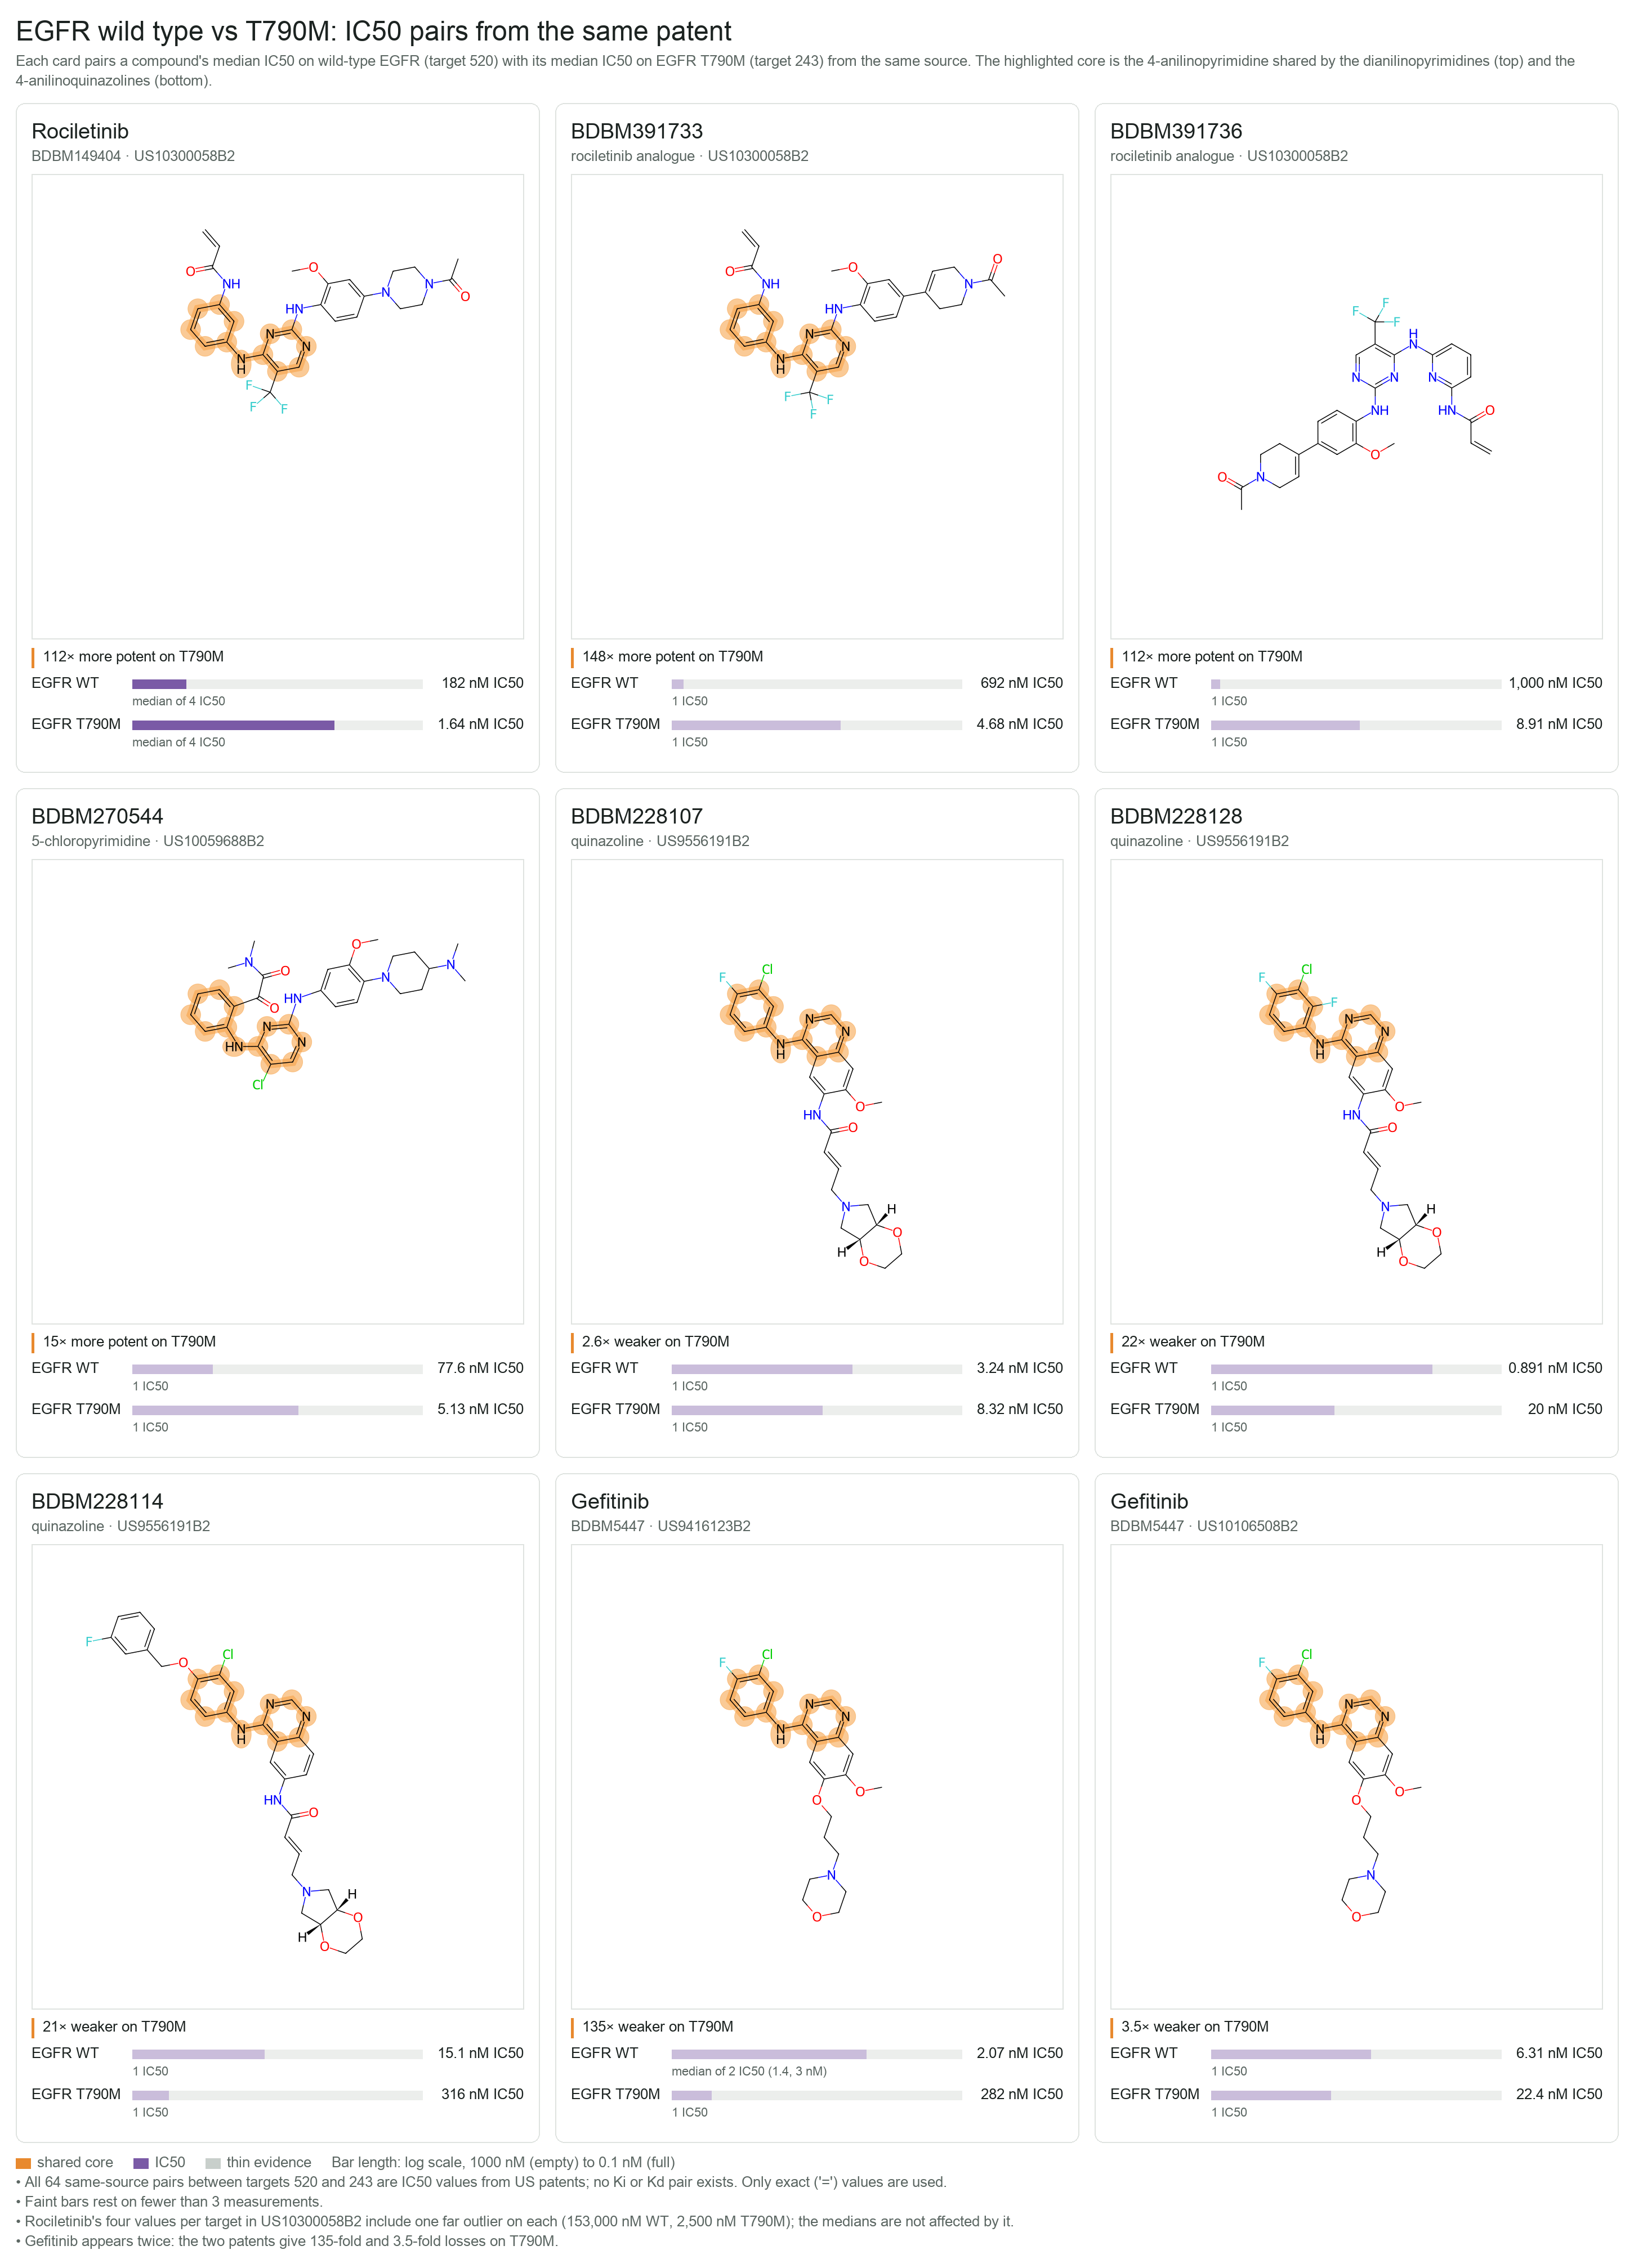

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'EGFR wild type vs T790M: IC50 pairs from the same patent',
    'compounds': [
        {
            'smiles': 'CC(=O)N1CCN(CC1)c2ccc(c(c2)OC)Nc3ncc(c(n3)Nc4cccc(c4)NC(=O)C=C)C(F)(F)F',
            'title': 'Rociletinib',
            'subtitle': 'BDBM149404 · US10300058B2',
            'caption': '112× more potent on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 182.0, 'type': 'IC50', 'note': 'median of 4 IC50'},
                {'label': 'EGFR T790M', 'value_nm': 1.64, 'type': 'IC50', 'note': 'median of 4 IC50'},
            ],
        },
        {
            'smiles': 'COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)c2)n1)C(F)(F)F)C1=CCN(CC1)C(C)=O |t:34|',
            'title': 'BDBM391733',
            'subtitle': 'rociletinib analogue · US10300058B2',
            'caption': '148× more potent on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 692.0, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {'label': 'EGFR T790M', 'value_nm': 4.68, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
            ],
        },
        {
            'smiles': 'COc1cc(ccc1Nc1ncc(c(Nc2cccc(NC(=O)C=C)n2)n1)C(F)(F)F)C1=CCN(CC1)C(C)=O |t:34|',
            'title': 'BDBM391736',
            'subtitle': 'rociletinib analogue · US10300058B2',
            'caption': '112× more potent on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 1000.0, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {'label': 'EGFR T790M', 'value_nm': 8.91, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
            ],
        },
        {
            'smiles': 'COc1cc(Nc2ncc(Cl)c(Nc3ccccc3C(=O)C(=O)N(C)C)n2)ccc1N1CCC(CC1)N(C)C',
            'title': 'BDBM270544',
            'subtitle': '5-chloropyrimidine · US10059688B2',
            'caption': '15× more potent on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 77.6, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {'label': 'EGFR T790M', 'value_nm': 5.13, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
            ],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1C[C@H]2OCCO[C@H]2C1',
            'title': 'BDBM228107',
            'subtitle': 'quinazoline · US9556191B2',
            'caption': '2.6× weaker on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 3.24, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {'label': 'EGFR T790M', 'value_nm': 8.32, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
            ],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3ccc(F)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C[C@H]2OCCO[C@H]2C1 |r|',
            'title': 'BDBM228128',
            'subtitle': 'quinazoline · US9556191B2',
            'caption': '22× weaker on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 0.891, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {'label': 'EGFR T790M', 'value_nm': 20.0, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
            ],
        },
        {
            'smiles': 'Fc1cccc(COc2ccc(Nc3ncnc4ccc(NC(=O)\\C=C\\CN5C[C@H]6OCCO[C@H]6C5)cc34)cc2Cl)c1 |r|',
            'title': 'BDBM228114',
            'subtitle': 'quinazoline · US9556191B2',
            'caption': '21× weaker on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 15.1, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {
                    'label': 'EGFR T790M',
                    'value_nm': 316.0,
                    'type': 'IC50',
                    'note': '1 IC50',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F',
            'title': 'Gefitinib',
            'subtitle': 'BDBM5447 · US9416123B2',
            'caption': '135× weaker on T790M',
            'bars': [
                {
                    'label': 'EGFR WT',
                    'value_nm': 2.07,
                    'type': 'IC50',
                    'note': 'median of 2 IC50 (1.4, 3 nM)',
                    'faint': True,
                },
                {
                    'label': 'EGFR T790M',
                    'value_nm': 282.0,
                    'type': 'IC50',
                    'note': '1 IC50',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F',
            'title': 'Gefitinib',
            'subtitle': 'BDBM5447 · US10106508B2',
            'caption': '3.5× weaker on T790M',
            'bars': [
                {'label': 'EGFR WT', 'value_nm': 6.31, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
                {'label': 'EGFR T790M', 'value_nm': 22.4, 'type': 'IC50', 'note': '1 IC50', 'faint': True},
            ],
        },
    ],
    'align_to': 'c1ccccc1Nc1ccncn1',
    'columns': 3,
    'description': "Each card pairs a compound's median IC50 on wild-type EGFR (target 520) with its median IC50 on EGFR T790M (target 243) from the same source. The highlighted core is the 4-anilinopyrimidine shared by the dianilinopyrimidines (top) and the 4-anilinoquinazolines (bottom).",
    'notes': [
        "All 64 same-source pairs between targets 520 and 243 are IC50 values from US patents; no Ki or Kd pair exists. Only exact ('=') values are used.",
        'Faint bars rest on fewer than 3 measurements.',
        "Rociletinib's four values per target in US10300058B2 include one far outlier on each (153,000 nM WT, 2,500 nM T790M); the medians are not affected by it.",
        'Gefitinib appears twice: the two patents give 135-fold and 3.5-fold losses on T790M.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

In BindingDB, EGFR mutants are separate targets that share the UniProt accession P00533 and carry the mutation in brackets. Searching for "EGFR" in human returns wild-type EGFR plus more than a dozen variants. The two compared here:

| Target id | Target | Compounds | Measurements |
|---|---|---|---|
| 520 | EGFR (wild type) | 14,127 | 23,267 |
| 243 | EGFR [T790M] | 213 | 229 |

Other variants hold more data than T790M alone. The double mutant [T790M, L858R] (target 60) has 1,276 compounds, and [L858R, T790M, C797S] (target 1058) has 679. T790M is the "gatekeeper" resistance mutation that lets lung tumours escape first-generation drugs such as gefitinib and erlotinib.

**A fair comparison.** I kept only exact ("=") Ki, Kd or IC50 values and compared each compound's wild-type and T790M values within the same source (same paper or patent, same affinity type). This gives 61 compounds (64 compound–source pairs) from 11 US patents. All 64 pairs turn out to be IC50 values; no paper or patent reports a Ki or Kd on both targets. Of these, 26 pairs are at least 10-fold more potent on T790M, 4 are at least 10-fold more potent on wild type, and the median shift is +0.4 log units toward the mutant.

The grid below shows nine of these pairs: each compound with one bar for its wild-type IC50 and one for its T790M IC50 from the same patent, and the fold change under the structure. The top four are mutant-selective, the bottom five lose potency on the mutant. Most bars are faint because each rests on one or two measurements; only rociletinib has four values per target. The 4-anilinopyrimidine core is highlighted in eight of the nine; BDBM391736 carries a 2-aminopyridine in place of the aniline, so it lacks the core and is drawn unaligned.

Two chemotypes separate cleanly. The 2,4-diaminopyrimidines (rociletinib and two of its acrylamide analogues from patent US10300058B2, and a 5-chloropyrimidine from US10059688B2) are designed to be mutant-selective, and they are 15- to 148-fold more potent on T790M. The 4-anilinoquinazolines (gefitinib and the acrylamide-bearing quinazolines of US9556191B2) lose potency on the mutant, by 2.6- to 135-fold. That is the drug-resistance mechanism, visible directly in the data. The fourth pair that is at least 10-fold wild-type selective is not drawn: an aminopyrazole from US9416123B2 (BDBM50379214), with a median IC50 of 110 nM on wild type (three values) and about 2.6 µM on T790M (two values).

**Lesson:** compare like with like. Gefitinib appears twice in the grid, and the two patents disagree: 135-fold weaker on T790M in one, only 3.5-fold weaker in the other. Assay format, ATP concentration and enzyme construct all shift IC50 values. Comparing a wild-type value from one paper with a mutant value from another can produce or hide a selectivity window. Pair measurements by source, as done here, before drawing conclusions, and look at the individual values: rociletinib's four values per target in US10300058B2 include one far outlier on each (153,000 nM on wild type, 2,500 nM on T790M), which the median absorbs but a mean would not. The same patent also gives eleven of its other analogues wild-type IC50s of 11 µM to 1.4 mM, with T790M values about 100-fold lower; the fold changes are consistent with the rest of the series, but values that high suggest a unit problem in those rows, so read their absolute potencies with care. Also note that find_ligands_for_target with include_variants=true pools all EGFR variants into one ranked list. That is useful for a quick overview, but to compare variants, query each variant's target id separately.

### How this was answered

- **search_targets** with query "EGFR", organism "Homo sapiens": listed wild-type EGFR (id 520) and its mutant and truncated constructs, including T790M (id 243).
- **find_ligands_for_target** with uniprot P00533, include_variants true: a pooled ranking across all EGFR variants. Wild-type measurements and recent patent data on other mutant constructs (mostly US20250034165 on T790M and triple-mutant constructs) fill the top of the list; T790M alone (target 243) does not appear in the top 50.
- **run_sql** on the activity table: paired each compound's median pAffinity on targets 520 and 243 within the same source and affinity type, counted the pairs and fold changes, and joined to compound for names and structures.
- **draw_structure_grid**: nine compound–patent pairs, each with a wild-type and a T790M IC50 bar, aligned on the 4-anilinopyrimidine shared by both chemotypes (given as `c1ccccc1Nc1ccncn1`, 13 atoms). Left to find the core itself, the tool chose an 8-atom methoxybenzene, which does not separate the chemotypes, so the grid was drawn again on the anilinopyrimidine.

### Try next

- "Show me the assay details behind the most potent gefitinib measurement on EGFR." (Example 3.4)
- "Find close analogues of rociletinib that are potent on EGFR T790M/L858R." (similarity search with a target filter, Example 2.2)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 3 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 3.3 — Mutant vs wild type (EGFR T790M), 2026-11-23, with claude-opus-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```